In [1]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}
from rdkit import Chem
from rdkit.Chem import Descriptors
# pd.set_option('display.max_rows', None)

In [2]:
# h298_df = pd.read_csv('tests/data/gdb11_0.001.csv')
h298_df = pd.read_csv('tests/data/gdb11_0.01.csv')
h298_df.describe()

,h298
count,71161.000000
mean,-1.357522
std,59.770424
min,-343.774000
25%,-40.303000
50%,0.903000
75%,40.292000
max,253.086000


In [3]:
# calculate statistics for molecular weight of smiles in h298_df using Descriptors.ExactMolWt()
h298_df['MW'] = h298_df['smiles'].apply(lambda x: Descriptors.ExactMolWt(Chem.MolFromSmiles(x)))
h298_df['MW'].describe()

count    71161.000000
mean       150.845469
std          7.529037
min         72.021129
25%        149.120449
50%        153.078979
75%        155.131014
max        174.050379
Name: MW, dtype: float64

In [4]:
# specify the root directory
root_dir = 'results'

dfs = []

# iterate over the directories in the root directory
for subdir in os.listdir(root_dir):
    subdir_path = os.path.join(root_dir, subdir)
    if os.path.isdir(subdir_path):
        
        # specify important files in the subdirectory
        json_path = os.path.join(subdir_path, "args.json")
        csv_path = os.path.join(subdir_path, "test_metrics.csv")
        
        # read in args.json
        with open(json_path, 'r') as f:
            json_data = json.load(f)
        json_df = pd.DataFrame({k:[v] for k, v in json_data.items()})
        
        # read in test_metrics.csv
        try:
            csv_df = pd.read_csv(csv_path)
        except FileNotFoundError:  # if job didn't finish, there'll be no CSV
            continue
        
        # concatentate horizontally
        df = pd.DataFrame({"directory": [subdir]})
        df = pd.concat([df, json_df, csv_df], axis=1)
        dfs.append(df)
                    
# combine the data into a single DataFrame
df = pd.concat(dfs, ignore_index=True)
df.drop(columns=['hf_col_name', 'lf_col_name', 'save_test_plot', 
                 'num_epochs', 'export_train_and_val', 'scale_data',
                 'results_dir'], inplace=True)

# df = df[df['split_type'] == 'random']
# df = df[df['split_type'] == 'scaffold']
df = df[df['split_type'] == 'h298']
# df = df[df['split_type'] == 'molwt']
# df = df[df['split_type'] == 'atom']

df['data_file'] = df['data_file'].apply(lambda x: float(x.split('/')[-1].split('_')[-1][:-4]))

df = df[df['data_file'] == 0.001]

df.sort_values(by=['model_type', 'data_file', 'add_pn_bias_to_make_lf', 'add_constant_bias_to_make_lf', 'add_gauss_noise_to_make_lf', 'add_descriptor_bias_to_make_lf', 'lf_hf_size_ratio'])

,directory,model_type,data_file,add_pn_bias_to_make_lf,add_constant_bias_to_make_lf,add_gauss_noise_to_make_lf,add_descriptor_bias_to_make_lf,split_type,lf_hf_size_ratio,lf_superset_of_hf,seed,MAE_hf,RMSE_hf,R2_hf,MAE_lf,RMSE_lf,R2_lf
167,2023-11-05_17-33-49.077575,delta_ml,0.001,0,0.0,0.0,0.0,h298,1,False,0,79.379951,80.387777,-3.149416,NaN,NaN,NaN
722,2023-11-05_02-34-02.432801,delta_ml,0.001,0,0.0,0.0,0.0,h298,1,False,1,70.972164,74.338741,-2.548439,NaN,NaN,NaN
1018,2023-11-05_18-19-23.968240,delta_ml,0.001,0,0.0,0.0,0.0,h298,1,True,1,60.350519,65.882966,-1.787104,NaN,NaN,NaN
1370,2023-11-05_02-31-00.193286,delta_ml,0.001,0,0.0,0.0,0.0,h298,1,False,1,102.355912,102.953035,-5.805895,NaN,NaN,NaN
1552,2023-11-05_17-20-23.821280,delta_ml,0.001,0,0.0,0.0,0.0,h298,1,True,0,96.402684,96.454856,-4.973862,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3069,2023-11-05_06-04-37.576571,transfer,0.001,3,0.0,0.0,0.0,h298,100,True,1,20.479530,26.657998,-0.402629,166369.518046,212015.554632,-0.276067
3565,2023-11-05_06-22-09.218155,transfer,0.001,3,0.0,0.0,0.0,h298,100,False,1,21.151337,27.489441,-0.491488,171112.791702,212473.307307,-0.270305
4307,2023-11-05_04-50-52.250367,transfer,0.001,3,0.0,0.0,0.0,h298,100,True,2,42.414588,60.359950,-0.751108,134232.218748,162730.626743,-0.412093
7166,2023-11-05_05-07-44.500588,transfer,0.001,3,0.0,0.0,0.0,h298,100,False,2,39.910873,56.922408,-0.557334,127815.081261,159504.807114,-0.371703


In [5]:
df = df.loc[(df.model_type != "trad_delta_ml") & (df.model_type != "multi_fidelity_weight_sharing")]

In [6]:
kl_divergences = {
    1: {
        True: 0.0, 
        False: 0.31375520824244774,
        },
    10: {
        True: 0.8069744049719612,
        False: 1.3056845081867896,
        },
    100: {
        True: 76.76828858563738,
        False: 78.57271071926694,
        },
}

In [7]:
df['kl_divergence'] = df.apply(lambda x: kl_divergences[x['lf_hf_size_ratio']][x['lf_superset_of_hf']], axis=1)
df

,directory,model_type,data_file,add_pn_bias_to_make_lf,add_constant_bias_to_make_lf,add_gauss_noise_to_make_lf,add_descriptor_bias_to_make_lf,split_type,lf_hf_size_ratio,lf_superset_of_hf,seed,MAE_hf,RMSE_hf,R2_hf,MAE_lf,RMSE_lf,R2_lf,kl_divergence
2,2023-11-05_14-28-12.012774,multi_target,0.001,0,0.0,0.0,10.0,h298,1,True,1,83.036194,84.913259,-3.629755,92.950711,94.349361,-3.616544,0.000000
6,2023-11-05_02-33-01.074632,delta_ml,0.001,0,50.0,0.0,0.0,h298,1,False,1,67.103550,76.348821,-2.742929,NaN,NaN,NaN,0.313755
7,2023-11-05_09-14-34.128109,multi_fidelity,0.001,0,0.0,0.0,10.0,h298,1,False,1,91.411278,93.359063,-4.596544,74.911406,81.284609,-2.426539,0.313755
9,2023-11-05_04-55-07.558054,transfer,0.001,0,0.0,0.0,0.0,h298,1,True,1,85.842778,87.597024,-3.927035,85.842778,87.597024,-3.927035,0.000000
15,2023-11-05_04-49-48.059268,transfer,0.001,2,0.0,0.0,0.0,h298,100,True,2,55.991049,77.317096,-1.873203,929.218135,1337.233316,-1.704229,76.768289
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8418,2023-11-05_17-51-31.160541,delta_ml,0.001,2,0.0,0.0,0.0,h298,1,True,2,64.949798,84.691007,-3.605551,NaN,NaN,NaN,0.000000
8421,2023-11-05_07-01-45.899410,transfer,0.001,3,0.0,0.0,0.0,h298,100,True,0,40.903941,45.563423,-0.308542,100583.411085,123293.759850,-0.346031,76.768289
8438,2023-11-05_14-30-43.515799,multi_target,0.001,0,0.0,0.0,0.0,h298,1,True,1,78.762354,81.032199,-3.216210,73.532241,76.567595,-2.764410,0.000000
8447,2023-11-05_06-28-54.996856,transfer,0.001,0,0.0,50.0,0.0,h298,100,False,1,24.234203,27.730562,-0.517767,69.799692,83.101976,-0.644205,78.572711


In [8]:
df_mean = df.drop(columns=['directory']).groupby(['model_type', 'data_file', 'add_pn_bias_to_make_lf', 'add_constant_bias_to_make_lf',
            'add_gauss_noise_to_make_lf', 'add_descriptor_bias_to_make_lf', 'lf_hf_size_ratio', 'lf_superset_of_hf', 'split_type']).mean().reset_index()
df_std = df.drop(columns=['directory']).groupby(['model_type', 'data_file', 'add_pn_bias_to_make_lf', 'add_constant_bias_to_make_lf',
            'add_gauss_noise_to_make_lf', 'add_descriptor_bias_to_make_lf', 'lf_hf_size_ratio', 'lf_superset_of_hf', 'split_type']).std().reset_index()

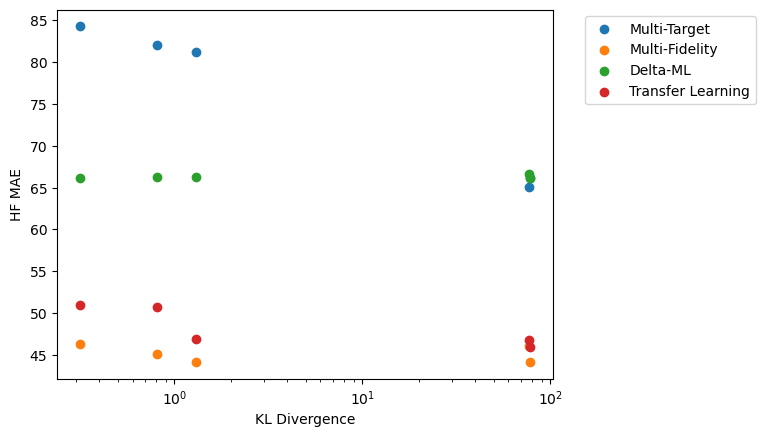

In [17]:
models_colors_dict = {
    'single_fidelity': 'k',
    'multi_target': 'b',
    'multi_fidelity': 'r',
    'delta_ml': 'c',
    'trad_delta_ml': 'm',
    'transfer': 'g',
    'multi_fidelity_weight_sharing': 'y',
}

model_type_dict = {
    'single_fidelity': 'Single Fidelity',
    'multi_target': 'Multi-Target',
    'multi_fidelity': 'Multi-Fidelity',
    'delta_ml': 'Delta-ML',
    'trad_delta_ml': 'Traditional Delta-ML',
    'transfer': 'Transfer Learning',
    'multi_fidelity_weight_sharing': 'Multi-Fidelity WS',
}

# for lf_hf_size_ratio in [1, 10, 100]:
#     for lf_superset_of_hf in [True, False]:
default_var_values = {
    'add_pn_bias_to_make_lf': 2, 
    'add_constant_bias_to_make_lf': 0.0, 
    'add_gauss_noise_to_make_lf': 0.0,	
    'add_descriptor_bias_to_make_lf': 0.0, 
    # 'lf_hf_size_ratio': lf_hf_size_ratio,
    # 'lf_superset_of_hf': lf_superset_of_hf,
}

df_mean_ = df_mean.loc[
    (df_mean.add_pn_bias_to_make_lf == default_var_values['add_pn_bias_to_make_lf']) & \
    (df_mean.add_constant_bias_to_make_lf == default_var_values['add_constant_bias_to_make_lf']) & \
    (df_mean.add_gauss_noise_to_make_lf == default_var_values['add_gauss_noise_to_make_lf']) & \
    (df_mean.add_descriptor_bias_to_make_lf == default_var_values['add_descriptor_bias_to_make_lf'])]

df_std_ = df_std.loc[
    (df_std.add_pn_bias_to_make_lf == default_var_values['add_pn_bias_to_make_lf']) & \
    (df_std.add_constant_bias_to_make_lf == default_var_values['add_constant_bias_to_make_lf']) & \
    (df_std.add_gauss_noise_to_make_lf == default_var_values['add_gauss_noise_to_make_lf']) & \
    (df_std.add_descriptor_bias_to_make_lf == default_var_values['add_descriptor_bias_to_make_lf'])]

# plot MAE vs. KL divergence with each model type in a different color
fig, ax = plt.subplots()
for model_type, color in models_colors_dict.items():
    df_model = df_mean_[df_mean_['model_type'] == model_type]
    if len(df_model) == 0:
        continue
    # ax.errorbar(df_model['kl_divergence'], df_model['MAE_hf'], yerr=df_std_[df_std_['model_type'] == model_type]['MAE_hf'], fmt='o', label=model_type_dict[model_type], color=color)
    ax.scatter(df_model['kl_divergence'], df_model['MAE_hf'], label=model_type_dict[model_type])  #, color=color)
ax.set_xlabel('KL Divergence')
ax.set_ylabel('HF MAE')
# ax.set_xscale('log')
# ax.set_yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()